# Simulation of Inhomogeneous Boltzmann Equation
### Conservative Semi-Lagrangian Method Coupled with Fast Spectral Collision Solver

---
### 1. Overview and Problem Description
In kinetic theory, the spatially inhomogeneous Boltzmann equation models the evolution of the one-particle distribution function $f(x, v, t)$ in phase space:

$$\frac{\partial f}{\partial t} + v \cdot \nabla_x f = \frac{1}{\varepsilon} Q(f, f)$$

where:
* $x \in \Omega_x \subset \mathbb{R}^{d_x}$ is the spatial coordinate,
* $v \in \mathbb{R}^{d_v}$ is the microscopic velocity,
* $\varepsilon > 0$ is the Knudsen number,
* $Q(f, f)$ is the nonlinear Boltzmann collision operator.

In this tutorial, we implement the state-of-the-art conservative semi-Lagrangian method proposed by **Boscarino, Cho, and Russo (2024)**, integrated with the fast spectral method for general collision kernels (**Gamba et al., 2017**).

#### Key Numerical Features:
1. **Semi-Lagrangian Transport**: Characteristics-based advection along velocity $v$ with high-order reconstruction (**CWENO35** / **CWENO23**).
2. **Fast Spectral Method**: Accurate evaluation of the collision operator $Q(f)$ in $O(M N_v^d \log N_v)$ complexity via discrete Fourier transform and spherical quadratures.
3. **Exact Conservation**: Moment-constrained $L^2$ projection guaranteeing conservation of mass, momentum, and energy to machine precision ($\sim 10^{-15}$).

#### References:
* [1] S. Boscarino, B. Cho, and G. Russo, *A Conservative Semi-Lagrangian Method for Inhomogeneous Boltzmann Equation*, **Journal of Computational Physics**, 498 (2024), 112678.
* [2] I. M. Gamba, J. R. Haack, C. D. Hauck, and J. Hu, *A Fast Spectral Method for the Boltzmann Collision Operator with General Collision Kernels*, **SIAM Journal on Scientific Computing**, 39 (2017), pp. B658–B674.



In [1]:
%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt

from deep_numerical.numerical.solver.fsm__boltzmann import FastSM_Boltzmann_VHS
from deep_numerical.utils import velocity_grid, space_grid

# Configure plot style and default precision
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120
torch.set_default_dtype(torch.float64)
print(f"PyTorch version: {torch.__version__}, default dtype: {torch.get_default_dtype()}")



PyTorch version: 2.14.1+cpu, default dtype: torch.float64


C:\Users\GJ2\deep_numerical\deep_numerical\utils\__init__.py:8: UserWarning: Module 'torch_geometric' is not installed. 'RandomGraphGenerator' and 'RandomGridGenerator' will not be available.
  from deep_numerical.utils._random_grid   import *


### 2. Benchmark Setup: Smooth Non-Equilibrium Problem (Boscarino et al. 2024, Test 1)
We adopt the 1D spatial, 2D velocity $(1D_x \times 2D_v)$ benchmark from **Boscarino, Cho, and Russo (2024, Section 5.1)** with updated parameter configurations:
* Spatial Domain: $x \in [-L_x, L_x]$ with $L_x = 1.0$, periodic boundary condition.
* Velocity Domain: $v = (v_x, v_y) \in [-V_{\max}, V_{\max}]^2$ with $V_{\max} = 6.0$.
* Initial non-equilibrium Maxwellian perturbation:
  $$\rho_0(x) = 1.0 + 0.4 \sin(\pi x)$$
  $$u_{x, 0}(x) = 0.5 (1 - \cos(\pi x)), \quad u_{y, 0}(x) = 0.0$$
  $$T_0(x) = 1.0 + 0.2 \cos(2\pi x)$$
  $$f_0(x, v) = \frac{\rho_0(x)}{2\pi T_0(x)} \exp\left( -\frac{|v - u_0(x)|^2}{2 T_0(x)} \right)$$


In [2]:
# Physical & Discretization Parameters
dim_v = 2
N_x   = 128          # Spatial grid resolution
N_v   = 32           # Velocity grid resolution per dimension
x_max = 1.0          # Spatial half-domain [-1, 1]
v_max = 6.0          # Velocity truncation limit [-6, 6]

t_init  = 0.0
t_final = 3.00       # Final physical simulation time
delta_t = 0.01       # Time step size (CFL condition satisfied)

knudsen = 1.0        # Knudsen number (Kn = 1: rarefied kinetic regime)
vhs_coeff = 1.0      # VHS collision kernel coefficient
vhs_alpha = 0.0      # VHS exponent (alpha = 0: Maxwellian molecules)

print(f"Spatial grid: {N_x} points, dx = {2 * x_max / (N_x - 1):.4f}")
print(f"Velocity grid: {N_v}x{N_v} points, dv = {2 * v_max / N_v:.4f}")



Spatial grid: 128 points, dx = 0.0157
Velocity grid: 32x32 points, dv = 0.3750


In [3]:
# Initialize Fast Spectral Boltzmann Solver
solver = FastSM_Boltzmann_VHS(
    dimension           = dim_v,
    v_num_grid          = N_v,
    v_max               = v_max,
    x_num_grid          = N_x,
    x_max               = x_max,
    vhs_coeff           = vhs_coeff,
    vhs_alpha           = vhs_alpha,
)

# Configure semi-Lagrangian transport parameters
solver.knudsen                = knudsen
solver.sl_scheme              = 'rk4'       # 4th-order Runge-Kutta time marching
solver.spatial_reconstruction = 'cweno35'   # 5th-order Central WENO reconstruction
solver.moment_correction      = True        # Enforce exact conservation of mass, momentum, energy

print("Solver successfully configured:")
print(f"  - Knudsen number: {solver.knudsen}")
print(f"  - Semi-Lagrangian scheme: {solver.sl_scheme}")
print(f"  - Spatial reconstruction: {solver.spatial_reconstruction}")
print(f"  - Moment correction: {solver.moment_correction}")



Solver successfully configured:
  - Knudsen number: 1.0
  - Semi-Lagrangian scheme: rk4
  - Spatial reconstruction: cweno35
  - Moment correction: True


In [4]:
# Generate 1D spatial coordinates and 2D velocity grid
x_coords = torch.linspace(-x_max, x_max, N_x)     # (N_x,)
v_grid   = velocity_grid(dim_v, N_v, v_max)       # (N_v, N_v, 2)
v_x      = v_grid[..., 0]                         # (N_v, N_v)
v_y      = v_grid[..., 1]                         # (N_v, N_v)

# Macroscopic fields at t = 0
rho_0 = 1.0 + 0.4 * torch.sin(torch.pi * x_coords)
u_x_0 = 0.5 * (1.0 - torch.cos(torch.pi * x_coords))
u_y_0 = torch.zeros_like(u_x_0)
T_0   = 1.0 + 0.2 * torch.cos(2 * torch.pi * x_coords)

# Reshape tensors to match library layout: (batch, space_x, space_y, vel_x, vel_y, value)
x_shape = (1, N_x, 1, 1, 1, 1)
v_shape = (1, 1, 1, N_v, N_v, 1)

rho_b = rho_0.view(*x_shape)
ux_b  = u_x_0.view(*x_shape)
uy_b  = u_y_0.view(*x_shape)
T_b   = T_0.view(*x_shape)

vx_b  = v_x.view(*v_shape)
vy_b  = v_y.view(*v_shape)

# Construct initial perturbed local Maxwellian
c_sq   = (vx_b - ux_b)**2 + (vy_b - uy_b)**2
f_init = (rho_b / (2.0 * torch.pi * T_b)) * torch.exp(-0.5 * c_sq / T_b)

print(f"Initial distribution function tensor shape: {f_init.shape}")



Initial distribution function tensor shape: torch.Size([1, 128, 1, 32, 32, 1])


### 3. Numerical Simulation: Solving the Inhomogeneous Boltzmann Equation
We call `solver.solve()` to advance the system from $t=0$ to $t=3.0$ with time step $\Delta t = 0.01$.


In [5]:
# Run solver
trajectory = solver.solve(
    t_init  = t_init,
    t_final = t_final,
    delta_t = delta_t,
    f_init  = f_init,
)

num_times = trajectory.shape[1]
time_array = np.linspace(t_init, t_final, num_times)
print(f"Simulation completed! Trajectory tensor shape: {trajectory.shape}")
print(f"Number of saved time frames: {num_times}")



  0%|          | 0/300 [00:00<?, ?it/s]

Simulation completed! Trajectory tensor shape: torch.Size([1, 301, 128, 1, 32, 32, 1])
Number of saved time frames: 301


In [6]:
# Compute macroscopic fluid moments across space and time
dv = 2.0 * v_max / N_v
dx = 2.0 * x_max / (N_x - 1)

f_traj = trajectory[0, :, :, 0, :, :, 0]  # shape: (num_times, N_x, N_v, N_v)

# Density: rho(t, x) = \int f dv
rho_traj = torch.sum(f_traj, dim=(-2, -1)) * (dv**2)

# Mean velocity: u_x(t, x) = (1/rho) \int v_x f dv
mom_x_traj = torch.sum(f_traj * v_x.view(1, 1, N_v, N_v), dim=(-2, -1)) * (dv**2)
u_x_traj   = mom_x_traj / rho_traj

# Mean velocity: u_y(t, x) = (1/rho) \int v_y f dv
mom_y_traj = torch.sum(f_traj * v_y.view(1, 1, N_v, N_v), dim=(-2, -1)) * (dv**2)
u_y_traj   = mom_y_traj / rho_traj

# Temperature: T(t, x) = (1 / 2 rho) \int |v - u|^2 f dv
c_x = v_x.view(1, 1, N_v, N_v) - u_x_traj.unsqueeze(-1).unsqueeze(-1)
c_y = v_y.view(1, 1, N_v, N_v) - u_y_traj.unsqueeze(-1).unsqueeze(-1)
c_sq_traj = c_x**2 + c_y**2
T_traj = 0.5 * torch.sum(f_traj * c_sq_traj, dim=(-2, -1)) * (dv**2) / rho_traj

print("Macroscopic moments computed successfully.")



Macroscopic moments computed successfully.


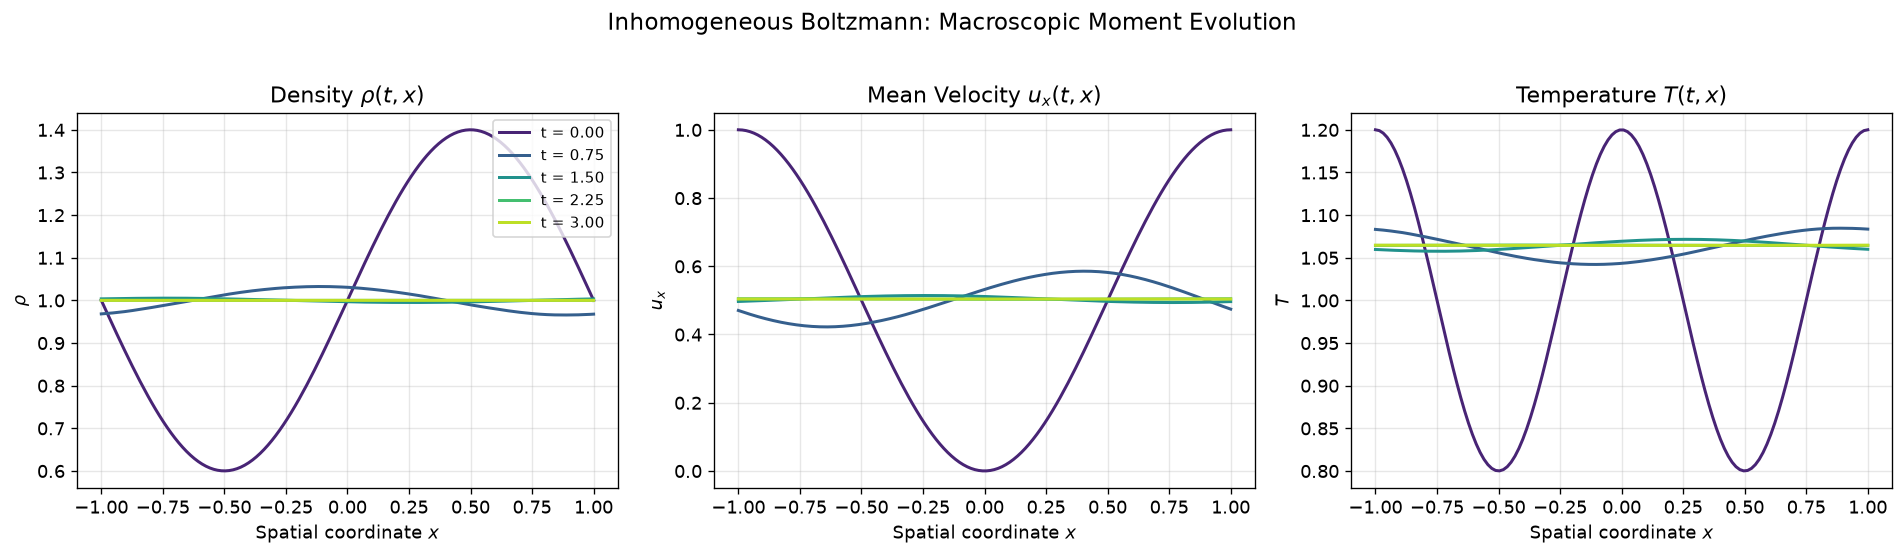

In [7]:
# Visualize spatial profile evolution of macroscopic moments
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

selected_indices = [0, num_times // 4, num_times // 2, 3 * num_times // 4, num_times - 1]
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(selected_indices)))

for idx, color in zip(selected_indices, colors):
    t_val = time_array[idx]
    label = f"t = {t_val:.2f}"
    
    # Density profile
    axes[0].plot(x_coords.numpy(), rho_traj[idx].numpy(), label=label, color=color, lw=1.8)
    # Velocity profile
    axes[1].plot(x_coords.numpy(), u_x_traj[idx].numpy(), label=label, color=color, lw=1.8)
    # Temperature profile
    axes[2].plot(x_coords.numpy(), T_traj[idx].numpy(), label=label, color=color, lw=1.8)

axes[0].set_title(r"Density $\rho(t, x)$")
axes[0].set_xlabel("Spatial coordinate $x$")
axes[0].set_ylabel(r"$\rho$")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper right", fontsize=9)

axes[1].set_title(r"Mean Velocity $u_x(t, x)$")
axes[1].set_xlabel("Spatial coordinate $x$")
axes[1].set_ylabel(r"$u_x$")
axes[1].grid(True, alpha=0.3)

axes[2].set_title(r"Temperature $T(t, x)$")
axes[2].set_xlabel("Spatial coordinate $x$")
axes[2].set_ylabel(r"$T$")
axes[2].grid(True, alpha=0.3)

plt.suptitle("Inhomogeneous Boltzmann: Macroscopic Moment Evolution", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()



### 4. Conservation Verification: Mass, Momentum, and Energy
Under periodic boundary conditions, the total macroscopic quantities in the phase space domain are strictly conserved:
$$\text{Mass}(t) = \iint f(x, v, t) \, dv \, dx$$
$$\text{Momentum}(t) = \iint v_x f(x, v, t) \, dv \, dx$$
$$\text{Energy}(t) = \iint \frac{1}{2} |v|^2 f(x, v, t) \, dv \, dx$$

Thanks to the $L^2$ moment projection method (`moment_correction=True`), the conservation error remains within machine precision.



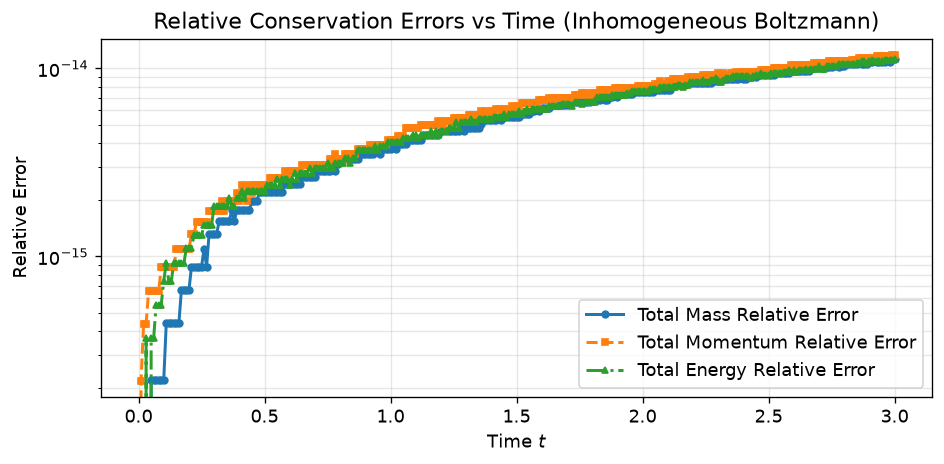

Max relative mass error:     1.12e-14
Max relative momentum error: 1.18e-14
Max relative energy error:   1.13e-14


In [8]:
# Total conserved quantities over time
v_sq_total = (v_x**2 + v_y**2).view(1, 1, N_v, N_v)

total_mass     = torch.sum(f_traj, dim=(1, 2, 3)) * (dv**2) * dx
total_momentum = torch.sum(f_traj * v_x.view(1, 1, N_v, N_v), dim=(1, 2, 3)) * (dv**2) * dx
total_energy   = 0.5 * torch.sum(f_traj * v_sq_total, dim=(1, 2, 3)) * (dv**2) * dx

rel_err_mass     = torch.abs(total_mass - total_mass[0]) / total_mass[0]
rel_err_momentum = torch.abs(total_momentum - total_momentum[0]) / (torch.abs(total_momentum[0]) + 1e-12)
rel_err_energy   = torch.abs(total_energy - total_energy[0]) / total_energy[0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(time_array, rel_err_mass.numpy(), 'o-', label="Total Mass Relative Error", lw=1.8, ms=4)
ax.semilogy(time_array, rel_err_momentum.numpy(), 's--', label="Total Momentum Relative Error", lw=1.8, ms=4)
ax.semilogy(time_array, rel_err_energy.numpy(), '^-.', label="Total Energy Relative Error", lw=1.8, ms=4)

ax.set_title("Relative Conservation Errors vs Time (Inhomogeneous Boltzmann)")
ax.set_xlabel("Time $t$")
ax.set_ylabel("Relative Error")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Max relative mass error:     {rel_err_mass.max().item():.2e}")
print(f"Max relative momentum error: {rel_err_momentum.max().item():.2e}")
print(f"Max relative energy error:   {rel_err_energy.max().item():.2e}")



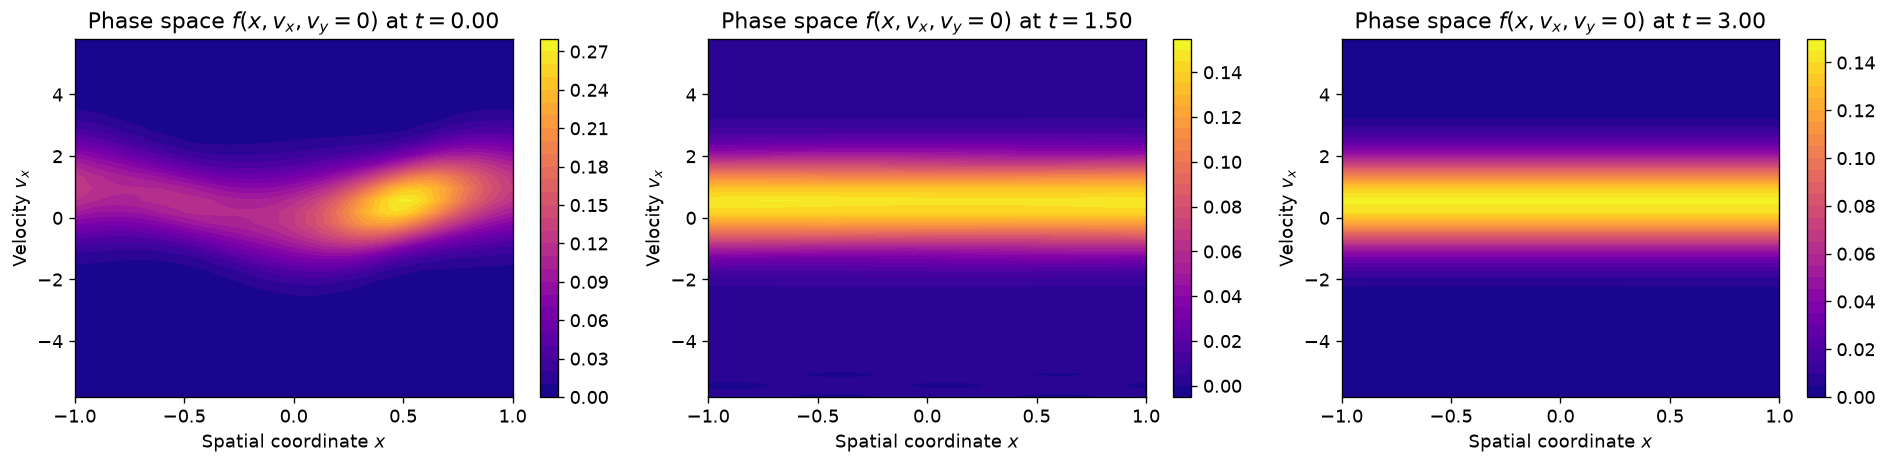

In [9]:
# 2D Phase-space contour plot f(x, v_x, v_y = 0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

times_to_plot = [0, num_times // 2, num_times - 1]
vy_zero_idx   = N_v // 2  # Slice along v_y ~= 0

X_grid, Vx_grid = np.meshgrid(x_coords.numpy(), v_x[:, vy_zero_idx].numpy(), indexing='ij')

for ax, t_idx in zip(axes, times_to_plot):
    f_slice = f_traj[t_idx, :, :, vy_zero_idx].numpy()
    cf = ax.contourf(X_grid, Vx_grid, f_slice, levels=30, cmap='plasma')
    plt.colorbar(cf, ax=ax)
    ax.set_title(f"Phase space $f(x, v_x, v_y=0)$ at $t={time_array[t_idx]:.2f}$")
    ax.set_xlabel("Spatial coordinate $x$")
    ax.set_ylabel("Velocity $v_x$")

plt.tight_layout()
plt.show()



End of file.
